# LAB 06 — Experiment 1: Attention Distribution

Câu mẫu: `The movie was surprisingly good despite a very slow beginning.`

Thí nghiệm này sử dụng query/key vectors giả lập để minh họa **unscaled dot-product attention**. Các vector không phải embedding đã học, vì vậy attention weight không phải đánh giá mức độ quan trọng về ngữ nghĩa.

## 1. Import và cấu hình dữ liệu

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from attention_numpy import dot_product_attention, stable_softmax

LAB_DIR = Path.cwd() if Path.cwd().name == 'Lab6' else Path.cwd() / 'Lab6'
if not (LAB_DIR / 'attention_numpy.py').is_file():
    LAB_DIR = Path.cwd()

ARTIFACTS_DIR = LAB_DIR / 'artifacts'
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

TOKENS = [
    'The', 'movie', 'was', 'surprisingly', 'good',
    'despite', 'a', 'very', 'slow', 'beginning'
]
QUERY = np.array([1.0, 0.5, -0.5, 0.25], dtype=np.float64)
SEED = 42
D_K = 4

def create_mock_attention_inputs(token_count, dimension, seed):
    # Query cố định và keys ngẫu nhiên có seed giúp thí nghiệm tái lập.
    query = np.array([1.0, 0.5, -0.5, 0.25], dtype=np.float64)
    if query.shape != (dimension,):
        raise ValueError('dimension cần bằng 4 theo cấu hình query của experiment')
    rng = np.random.default_rng(seed)
    keys = rng.normal(0.0, 1.0, size=(token_count, dimension)).astype(np.float64)
    return query, keys

QUERY, KEYS = create_mock_attention_inputs(len(TOKENS), D_K, SEED)
print('Tokens:', TOKENS)
print('T =', len(TOKENS), '| d_k =', D_K)
print('Query shape:', QUERY.shape)
print('Key matrix shape:', KEYS.shape)
print('Query vector:\n', QUERY)
print('Key matrix:\n', KEYS)

Tokens: ['The', 'movie', 'was', 'surprisingly', 'good', 'despite', 'a', 'very', 'slow', 'beginning']
T = 10 | d_k = 4
Query shape: (4,)
Key matrix shape: (10, 4)
Query vector:
 [ 1.    0.5  -0.5   0.25]
Key matrix:
 [[ 0.30471708 -1.03998411  0.7504512   0.94056472]
 [-1.95103519 -1.30217951  0.1278404  -0.31624259]
 [-0.01680116 -0.85304393  0.87939797  0.77779194]
 [ 0.0660307   1.12724121  0.46750934 -0.85929246]
 [ 0.36875078 -0.9588826   0.8784503  -0.04992591]
 [-0.18486236 -0.68092954  1.22254134 -0.15452948]
 [-0.42832782 -0.35213355  0.53230919  0.36544406]
 [ 0.41273261  0.430821    2.1416476  -0.40641502]
 [-0.51224273 -0.81377273  0.61597942  1.12897229]
 [-0.11394746 -0.84015648 -0.82448122  0.65059279]]


## 2. Kiểm tra dữ liệu và tính attention

In [2]:
assert len(TOKENS) == 10
assert TOKENS[0] == 'The' and TOKENS[-1] == 'beginning'
assert QUERY.shape == (4,)
assert KEYS.shape == (10, 4)
assert np.all(np.isfinite(QUERY)) and np.all(np.isfinite(KEYS))
assert QUERY.shape[0] == KEYS.shape[1]

# Hàm này tính score q^T k_i và softmax ổn định; không chia cho sqrt(d_k).
scores, attention_weights = dot_product_attention(QUERY, KEYS)
print('Raw scores:', scores)
print('Attention weights:', attention_weights)
print('Sum of attention weights:', attention_weights.sum())

max_index = int(np.argmax(attention_weights))
min_index = int(np.argmin(attention_weights))
print(f'Maximum: {TOKENS[max_index]} = {attention_weights[max_index]:.8f}')
print(f'Minimum: {TOKENS[min_index]} = {attention_weights[min_index]:.8f}')

Raw scores: [-0.35535939 -2.74510579 -0.68857412  0.18107351 -0.56239714 -1.17523018
 -0.77918817 -0.54428444 -0.94487573  0.04086311]
Attention weights: [0.12055712 0.01104941 0.0863932  0.20614021 0.09801161 0.05310403
 0.07890897 0.09980304 0.06686043 0.17917199]
Sum of attention weights: 0.9999999999999999
Maximum: surprisingly = 0.20614021
Minimum: movie = 0.01104941


## 3. Bảng Token | Score | Attention

In [3]:
print(f'{"Token":<15} {"Score":>16} {"Attention":>16}')
print('-' * 50)
for token, score, weight in zip(TOKENS, scores, attention_weights):
    print(f'{token:<15} {score:>16.8f} {weight:>16.8f}')
print('-' * 50)
print(f'{"SUM":<15} {"":>16} {attention_weights.sum():>16.10f}')

Token                      Score        Attention
--------------------------------------------------
The                  -0.35535939       0.12055712
movie                -2.74510579       0.01104941
was                  -0.68857412       0.08639320
surprisingly          0.18107351       0.20614021
good                 -0.56239714       0.09801161
despite              -1.17523018       0.05310403
a                    -0.77918817       0.07890897
very                 -0.54428444       0.09980304
slow                 -0.94487573       0.06686043
beginning             0.04086311       0.17917199
--------------------------------------------------
SUM                                  1.0000000000


## 4. Vẽ và lưu attention distribution

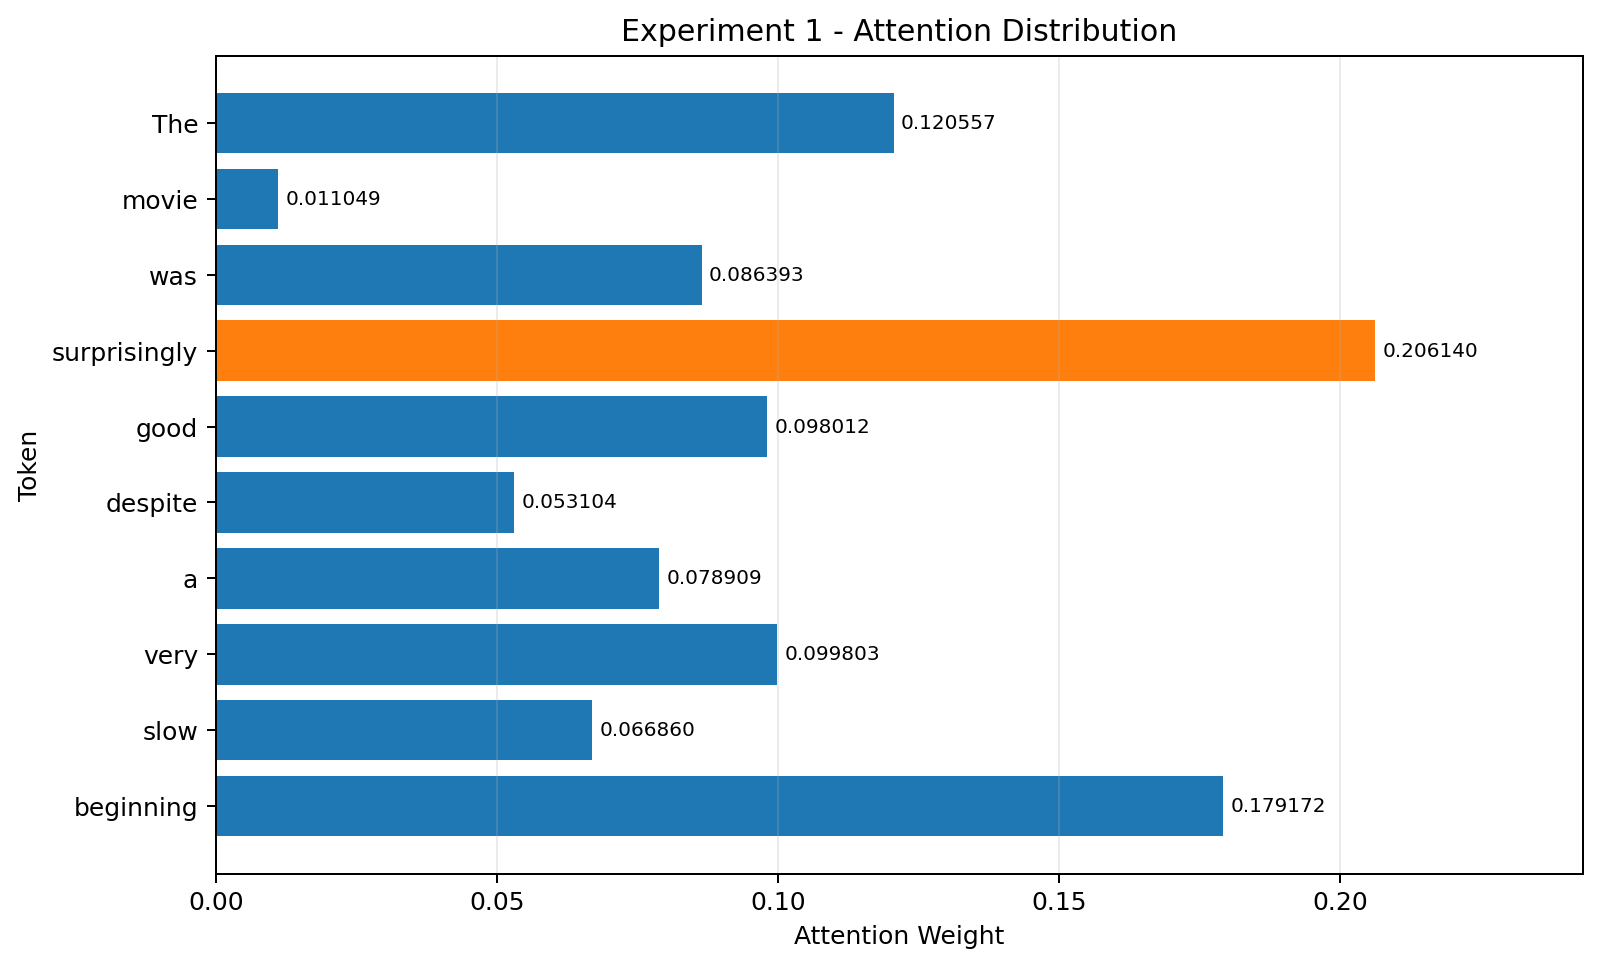

Saved: /home/nguyenducthang/NLP/Lab6/artifacts/experiment1_attention_distribution.png


In [4]:
colors = ['tab:orange' if i == max_index else 'tab:blue' for i in range(len(TOKENS))]
fig, ax = plt.subplots(figsize=(9, 5.5))
y_positions = np.arange(len(TOKENS))
bars = ax.barh(y_positions, attention_weights, color=colors)
ax.set_yticks(y_positions, TOKENS)
ax.invert_yaxis()  # Giữ token đầu câu ở hàng trên cùng.
ax.set_xlabel('Attention Weight')
ax.set_ylabel('Token')
ax.set_title('Experiment 1 - Attention Distribution')
ax.set_xlim(left=0, right=float(attention_weights.max()) * 1.18)
ax.bar_label(bars, fmt='%.6f', padding=3, fontsize=8)
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
png_path = ARTIFACTS_DIR / 'experiment1_attention_distribution.png'
fig.savefig(png_path, dpi=180, bbox_inches='tight')
display(Image(filename=str(png_path)))
print('Saved:', png_path)

## 5. Lưu kết quả CSV

In [5]:
csv_path = ARTIFACTS_DIR / 'experiment1_attention_distribution.csv'
with csv_path.open('w', newline='', encoding='utf-8') as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(['Token', 'Score', 'Attention'])
    writer.writerows(
        (token, f'{score:.12f}', f'{weight:.12f}')
        for token, score, weight in zip(TOKENS, scores, attention_weights)
    )
print('Saved:', csv_path)

Saved: /home/nguyenducthang/NLP/Lab6/artifacts/experiment1_attention_distribution.csv


## 6. Kiểm thử và reproducibility

In [6]:
# Kiểm tra shapes và số học của attention weights.
assert scores.shape == (10,) and attention_weights.shape == (10,)
assert np.isclose(attention_weights.sum(), 1.0, atol=1e-10)
assert np.all(attention_weights >= 0) and np.all(attention_weights <= 1)
assert np.all(np.isfinite(scores)) and np.all(np.isfinite(attention_weights))
large_score_weights = stable_softmax(np.array([1000.0, 1001.0, 1002.0]))
assert np.all(np.isfinite(large_score_weights))
assert np.isclose(large_score_weights.sum(), 1.0, atol=1e-10)

# Softmax bảo toàn thứ tự scores: score lớn hơn thì weight cũng lớn hơn.
for i in range(len(scores)):
    for j in range(len(scores)):
        if scores[i] > scores[j]:
            assert attention_weights[i] > attention_weights[j]

# Chạy lại với cùng seed để xác nhận dữ liệu và kết quả tái lập.
query_again, keys_again = create_mock_attention_inputs(len(TOKENS), D_K, SEED)
scores_again, weights_again = dot_product_attention(query_again, keys_again)
assert np.array_equal(QUERY, query_again)
assert np.array_equal(KEYS, keys_again)
assert np.array_equal(scores, scores_again)
assert np.array_equal(attention_weights, weights_again)

# Kiểm tra CSV có đủ đúng 10 dòng dữ liệu và ba cột.
with csv_path.open(newline='', encoding='utf-8') as csv_file:
    csv_rows = list(csv.reader(csv_file))
assert csv_rows[0] == ['Token', 'Score', 'Attention']
assert len(csv_rows) == 11 and all(len(row) == 3 for row in csv_rows)
assert [row[0] for row in csv_rows[1:]] == TOKENS

assert png_path.is_file() and png_path.stat().st_size > 0
assert len(ax.patches) == 10
print('PASS: tokens, shapes, stable softmax, ordering, reproducibility, CSV, PNG')

PASS: tokens, shapes, stable softmax, ordering, reproducibility, CSV, PNG


## 7. Ghi nhận cho phần phân tích cá nhân

Notebook hiển thị score/weight lớn nhất, nhỏ nhất và tổng weights ở trên. Hãy tự nhận xét phân phối có phẳng hay tập trung, và giới hạn của query/key giả lập. Không xem token có weight cao nhất là token quan trọng nhất về ngữ nghĩa; thí nghiệm này không huấn luyện mô hình sentiment và không chứng minh reasoning.

# Experiment 2 — Query Variation

Giữ nguyên 10 token, key matrix, dot-product chưa scaling và softmax của Experiment 1. Chỉ đổi query. Nhãn Sentiment/Topic là tên minh họa cho hai query giả lập, không hàm ý các vector đã học ngữ nghĩa.

## 1. Thiết lập biến cố định và hai query

In [7]:
# Lưu lại trạng thái artifacts Experiment 1 để kiểm tra không bị ghi đè.
EXP1_CSV_PATH = ARTIFACTS_DIR / 'experiment1_attention_distribution.csv'
EXP1_PNG_PATH = ARTIFACTS_DIR / 'experiment1_attention_distribution.png'
EXP1_CSV_BEFORE = EXP1_CSV_PATH.read_bytes()
EXP1_PNG_BEFORE = EXP1_PNG_PATH.read_bytes()

# Tái sử dụng chính tokens, query và keys đã được tạo ở Experiment 1.
TOKENS_E2 = TOKENS.copy()
QUERY_A = QUERY.copy()
QUERY_B = np.array([0.25, -0.5, 0.5, 1.0], dtype=np.float64)
KEYS_E2 = KEYS  # Cả hai query sẽ truyền đúng cùng ma trận keys này.
TEMPERATURE_E2 = 1.0
SCALING_E2 = False  # Experiment 1 và 2 đều dùng dot product chưa scaling.

assert TOKENS_E2 == TOKENS
assert np.array_equal(KEYS_E2, KEYS)
assert not np.array_equal(QUERY_A, QUERY_B)
assert QUERY_A.shape == QUERY_B.shape == (4,)
assert np.isclose(np.linalg.norm(QUERY_A), np.linalg.norm(QUERY_B))
print('Sequence:', TOKENS_E2)
print('Query A — Sentiment:', QUERY_A, '| L2 norm:', np.linalg.norm(QUERY_A))
print('Query B — Topic:    ', QUERY_B, '| L2 norm:', np.linalg.norm(QUERY_B))
print('Shared key matrix shape:', KEYS_E2.shape)
print('Temperature:', TEMPERATURE_E2, '| scaled:', SCALING_E2)

Sequence: ['The', 'movie', 'was', 'surprisingly', 'good', 'despite', 'a', 'very', 'slow', 'beginning']
Query A — Sentiment: [ 1.    0.5  -0.5   0.25] | L2 norm: 1.25
Query B — Topic:     [ 0.25 -0.5   0.5   1.  ] | L2 norm: 1.25
Shared key matrix shape: (10, 4)
Temperature: 1.0 | scaled: False


## 2. Tính scores và attention weights

In [8]:
# Cùng hàm, cùng keys và cùng softmax; chỉ query thay đổi.
scores_a, weights_a = dot_product_attention(QUERY_A, KEYS_E2)
scores_b, weights_b = dot_product_attention(QUERY_B, KEYS_E2)

assert scores_a.shape == scores_b.shape == (10,)
assert weights_a.shape == weights_b.shape == (10,)
assert np.allclose(scores_a, KEYS_E2 @ QUERY_A)
assert np.allclose(scores_b, KEYS_E2 @ QUERY_B)
assert np.isclose(weights_a.sum(), 1.0, atol=1e-10)
assert np.isclose(weights_b.sum(), 1.0, atol=1e-10)
assert np.all(np.isfinite(scores_a)) and np.all(np.isfinite(scores_b))
assert np.all(np.isfinite(weights_a)) and np.all(np.isfinite(weights_b))
assert np.all((weights_a >= 0) & (weights_a <= 1))
assert np.all((weights_b >= 0) & (weights_b <= 1))

delta = weights_b - weights_a
absolute_diff = np.abs(delta)
same_distribution = np.allclose(weights_a, weights_b, rtol=1e-7, atol=1e-10)
tvd = 0.5 * np.sum(absolute_diff)
max_diff_index = int(np.argmax(absolute_diff))
top_a = int(np.argmax(weights_a))
top_b = int(np.argmax(weights_b))

print('Scores A:', scores_a)
print('Weights A:', weights_a, '| sum =', weights_a.sum())
print('Scores B:', scores_b)
print('Weights B:', weights_b, '| sum =', weights_b.sum())
print(f'Top A: {TOKENS_E2[top_a]} ({weights_a[top_a]:.8f})')
print(f'Top B: {TOKENS_E2[top_b]} ({weights_b[top_b]:.8f})')
print(f'Max |delta|: {TOKENS_E2[max_diff_index]} ({absolute_diff[max_diff_index]:.8f})')
print(f'Total Variation Distance: {tvd:.8f}')
print('Distributions differ (allclose):', not same_distribution)

Scores A: [-0.35535939 -2.74510579 -0.68857412  0.18107351 -0.56239714 -1.17523018
 -0.77918817 -0.54428444 -0.94487573  0.04086311]
Weights A: [0.12055712 0.01104941 0.0863932  0.20614021 0.09801161 0.05310403
 0.07890897 0.09980304 0.06686043 0.17917199] | sum = 0.9999999999999999
Scores B: [ 1.91196164 -0.08899143  1.6398126  -1.17265072  0.96092824  0.75099037
  0.70058348  0.55218144  1.71578769  0.62994355]
Weights B: [0.23277099 0.03147212 0.17731114 0.01064875 0.08992911 0.07289965
 0.06931608 0.05975631 0.19130732 0.06458854] | sum = 1.0
Top A: surprisingly (0.20614021)
Top B: The (0.23277099)
Max |delta|: surprisingly (0.19549146)
Total Variation Distance: 0.36779701
Distributions differ (allclose): True


## 3. Bảng so sánh theo token

In [9]:
print(f'{"Token":<15} {"Score A":>13} {"Weight A":>13} {"Score B":>13} {"Weight B":>13} {"Delta":>13}')
print('-' * 88)
for token, sa, wa, sb, wb, change in zip(TOKENS_E2, scores_a, weights_a, scores_b, weights_b, delta):
    print(f'{token:<15} {sa:>13.6f} {wa:>13.6f} {sb:>13.6f} {wb:>13.6f} {change:>13.6f}')
print('-' * 88)
print(f'{"SUM":<15} {"":>13} {weights_a.sum():>13.8f} {"":>13} {weights_b.sum():>13.8f}')

csv_path_e2 = ARTIFACTS_DIR / 'experiment2_query_comparison.csv'
with csv_path_e2.open('w', newline='', encoding='utf-8') as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(['Token', 'Score A', 'Weight A', 'Score B', 'Weight B', 'Delta'])
    writer.writerows(
        (token, f'{sa:.12f}', f'{wa:.12f}', f'{sb:.12f}', f'{wb:.12f}', f'{change:.12f}')
        for token, sa, wa, sb, wb, change in zip(TOKENS_E2, scores_a, weights_a, scores_b, weights_b, delta)
    )
print('Saved:', csv_path_e2)

Token                 Score A      Weight A       Score B      Weight B         Delta
----------------------------------------------------------------------------------------
The                 -0.355359      0.120557      1.911962      0.232771      0.112214
movie               -2.745106      0.011049     -0.088991      0.031472      0.020423
was                 -0.688574      0.086393      1.639813      0.177311      0.090918
surprisingly         0.181074      0.206140     -1.172651      0.010649     -0.195491
good                -0.562397      0.098012      0.960928      0.089929     -0.008082
despite             -1.175230      0.053104      0.750990      0.072900      0.019796
a                   -0.779188      0.078909      0.700583      0.069316     -0.009593
very                -0.544284      0.099803      0.552181      0.059756     -0.040047
slow                -0.944876      0.066860      1.715788      0.191307      0.124447
beginning            0.040863      0.179172      0.

## 4. Trực quan hóa hai phân phối

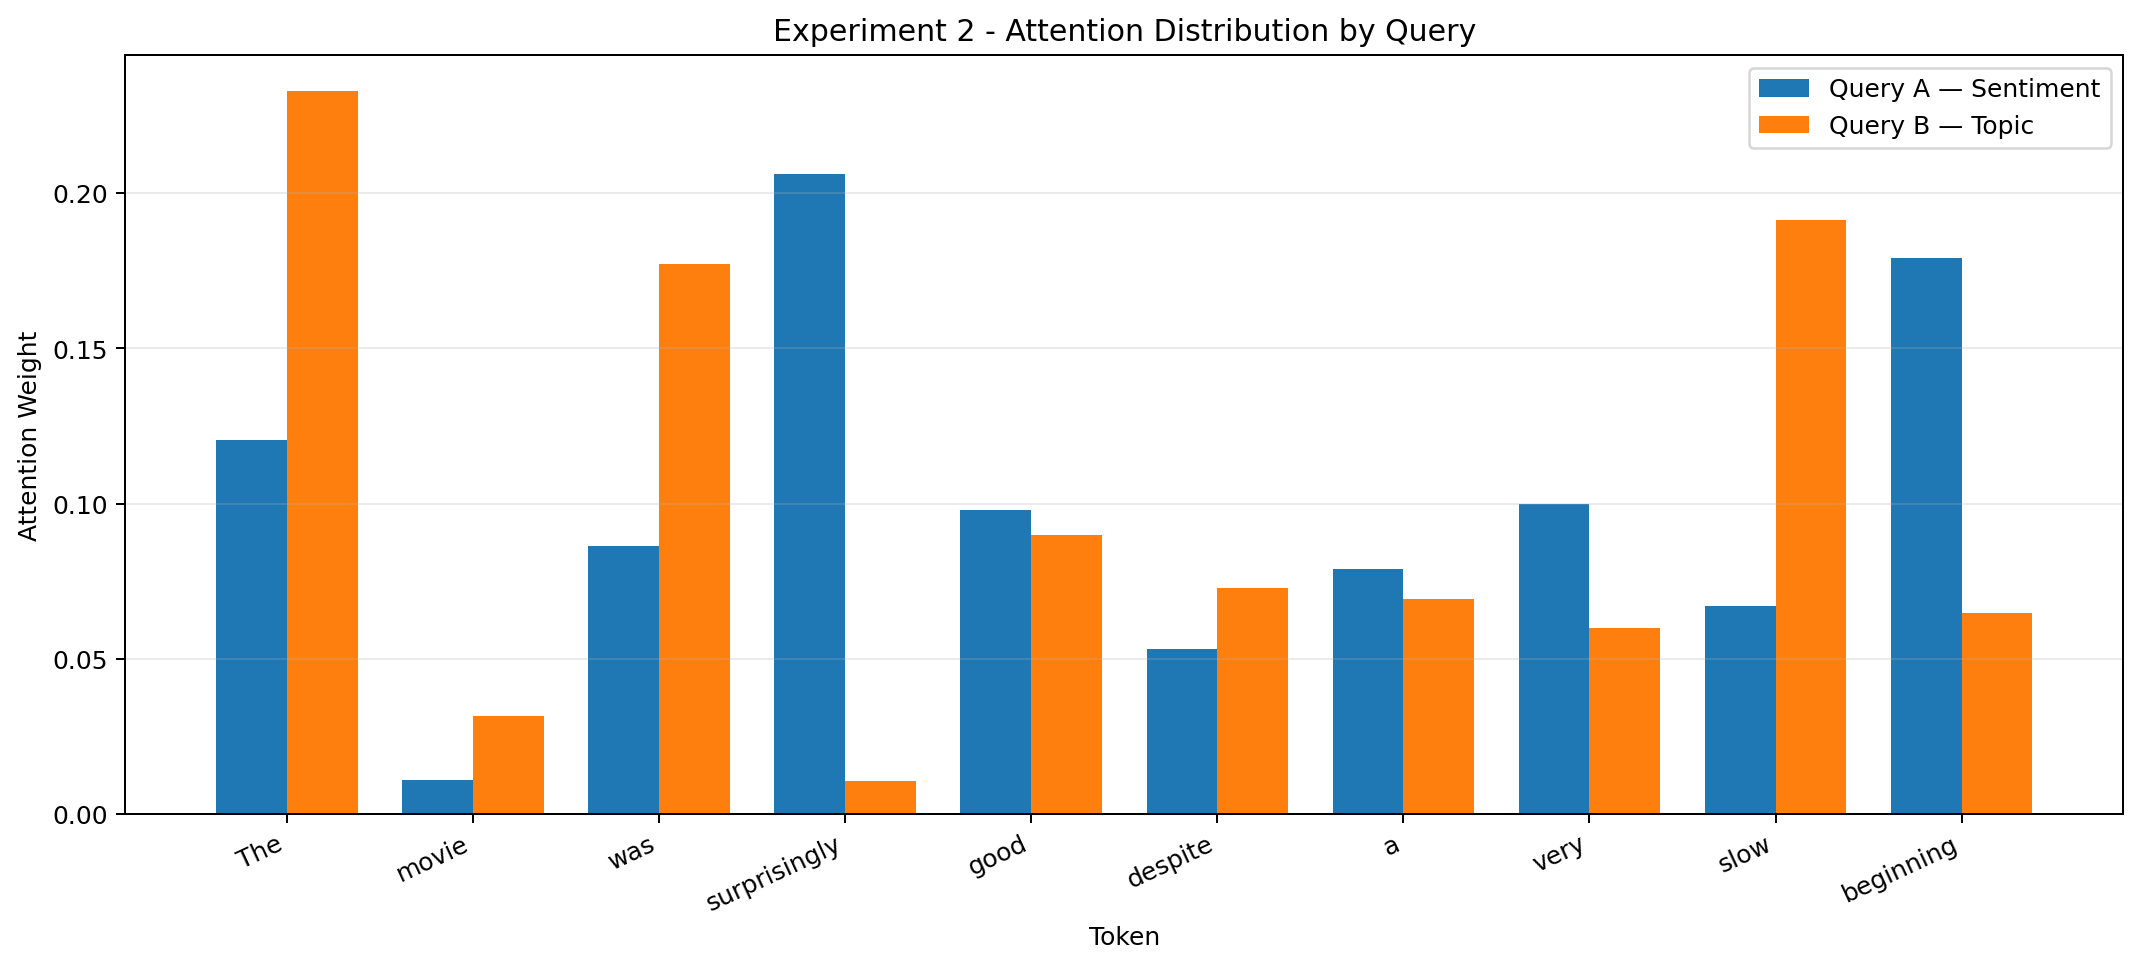

Saved: /home/nguyenducthang/NLP/Lab6/artifacts/experiment2_query_comparison.png


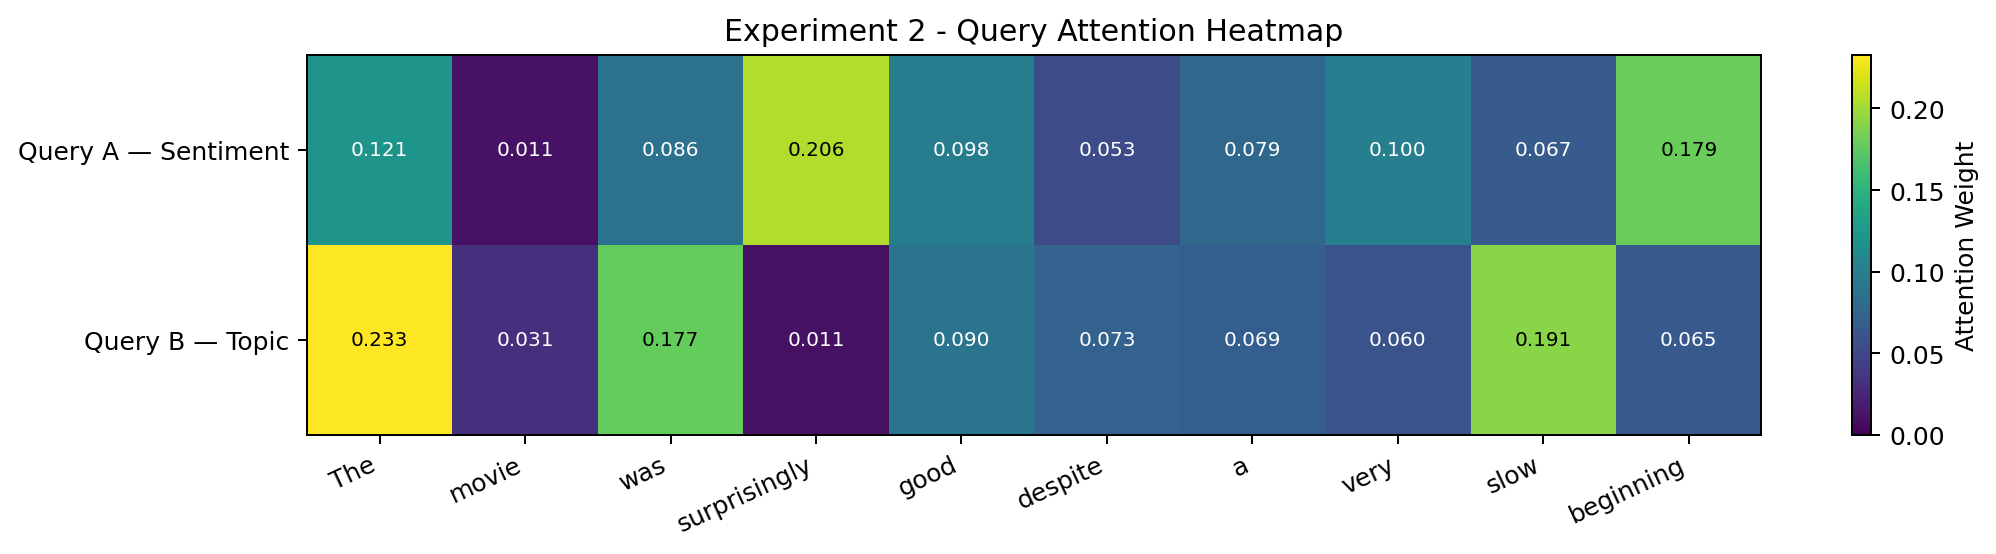

Saved: /home/nguyenducthang/NLP/Lab6/artifacts/experiment2_query_heatmap.png


In [10]:
x = np.arange(len(TOKENS_E2))
bar_width = 0.38
fig_compare, ax_compare = plt.subplots(figsize=(12, 5.5))
ax_compare.bar(x - bar_width / 2, weights_a, bar_width, label='Query A — Sentiment', color='tab:blue')
ax_compare.bar(x + bar_width / 2, weights_b, bar_width, label='Query B — Topic', color='tab:orange')
ax_compare.set_xticks(x, TOKENS_E2, rotation=25, ha='right')
ax_compare.set_ylim(bottom=0)
ax_compare.set_xlabel('Token')
ax_compare.set_ylabel('Attention Weight')
ax_compare.set_title('Experiment 2 - Attention Distribution by Query')
ax_compare.legend()
ax_compare.grid(axis='y', alpha=0.25)
fig_compare.tight_layout()
compare_png = ARTIFACTS_DIR / 'experiment2_query_comparison.png'
fig_compare.savefig(compare_png, dpi=180, bbox_inches='tight')
display(Image(filename=str(compare_png)))
print('Saved:', compare_png)

heatmap_values = np.vstack([weights_a, weights_b])
fig_heat, ax_heat = plt.subplots(figsize=(12, 3.2))
heat = ax_heat.imshow(heatmap_values, aspect='auto', cmap='viridis', vmin=0, vmax=float(heatmap_values.max()))
ax_heat.set_xticks(np.arange(len(TOKENS_E2)), TOKENS_E2, rotation=25, ha='right')
ax_heat.set_yticks([0, 1], ['Query A — Sentiment', 'Query B — Topic'])
ax_heat.set_title('Experiment 2 - Query Attention Heatmap')
for row in range(heatmap_values.shape[0]):
    for col in range(heatmap_values.shape[1]):
        text_color = 'white' if heatmap_values[row, col] < heatmap_values.max() * 0.55 else 'black'
        ax_heat.text(col, row, f'{heatmap_values[row, col]:.3f}', ha='center', va='center', color=text_color, fontsize=8)
fig_heat.colorbar(heat, ax=ax_heat, label='Attention Weight')
fig_heat.tight_layout()
heatmap_png = ARTIFACTS_DIR / 'experiment2_query_heatmap.png'
fig_heat.savefig(heatmap_png, dpi=180, bbox_inches='tight')
display(Image(filename=str(heatmap_png)))
print('Saved:', heatmap_png)

## 5. Kiểm thử, reproducibility và regression Experiment 1

In [11]:
# Query variation phải chỉ khác query; các điều kiện khác được giữ nguyên.
assert TOKENS_E2 == TOKENS and np.array_equal(KEYS_E2, KEYS)
assert not np.array_equal(QUERY_A, QUERY_B)
assert TEMPERATURE_E2 == 1.0 and SCALING_E2 is False
assert not same_distribution  # Nếu bằng nhau, cần báo cáo chứ không sửa dữ liệu.

# Re-run cùng inputs phải cho cùng scores và weights.
scores_a_again, weights_a_again = dot_product_attention(QUERY_A, KEYS_E2)
scores_b_again, weights_b_again = dot_product_attention(QUERY_B, KEYS_E2)
assert np.array_equal(scores_a, scores_a_again) and np.array_equal(weights_a, weights_a_again)
assert np.array_equal(scores_b, scores_b_again) and np.array_equal(weights_b, weights_b_again)

# Regression: kết quả và artifacts của Experiment 1 vẫn giữ nguyên.
scores_e1_check, weights_e1_check = dot_product_attention(QUERY, KEYS)
assert np.allclose(scores_e1_check, scores, atol=1e-12)
assert np.allclose(weights_e1_check, attention_weights, atol=1e-12)
assert EXP1_CSV_PATH.read_bytes() == EXP1_CSV_BEFORE
assert EXP1_PNG_PATH.read_bytes() == EXP1_PNG_BEFORE

# Output files and CSV structure.
for output_path in [csv_path_e2, compare_png, heatmap_png]:
    assert output_path.is_file() and output_path.stat().st_size > 0
with csv_path_e2.open(newline='', encoding='utf-8') as csv_file:
    rows_e2 = list(csv.reader(csv_file))
assert rows_e2[0] == ['Token', 'Score A', 'Weight A', 'Score B', 'Weight B', 'Delta']
assert len(rows_e2) == 11 and [row[0] for row in rows_e2[1:]] == TOKENS_E2
assert np.isclose(sum(float(row[2]) for row in rows_e2[1:]), 1.0, atol=1e-10)
assert np.isclose(sum(float(row[4]) for row in rows_e2[1:]), 1.0, atol=1e-10)
assert np.allclose([float(row[5]) for row in rows_e2[1:]], delta, atol=1e-12)
print('PASS: same sequence/keys, query-only change, shapes, normalization, finite values, reproducibility, regression, CSV and PNG')

PASS: same sequence/keys, query-only change, shapes, normalization, finite values, reproducibility, regression, CSV and PNG


## 6. Dữ liệu để tự phân tích

Các cell phía trên báo cáo top token, độ chênh lớn nhất và Total Variation Distance từ kết quả thực tế. Hãy tự trả lời: attention distribution có đổi không; hai query tập trung cùng token không; vì sao scores thay đổi khi chỉ query thay đổi; và vì sao nhãn Sentiment/Topic ở đây chỉ mang tính minh họa. Không diễn giải các trọng số như bằng chứng rằng vector giả lập đã hiểu sentiment/topic.

# Experiment 3 — Attention Visualization

Tạo self-attention matrix cho hai câu trong W6.pdf bằng synthetic embeddings và random projections. Cùng token dùng cùng embedding; hai câu dùng cùng WQ/WK/WV. Heatmap mô tả trọng số tính từ dữ liệu giả lập, không chứng minh hiểu ngữ pháp hay reasoning.

## 1. Input sentences, tokenization và self-attention computation

In [12]:
from experiment3_attention import (
    SENTENCE1, SENTENCE2, SELECTED_TOKENS, create_synthetic_parameters, run_experiment3
)
from attention_numpy import self_attention

# Chụp lại outputs trước đó để kiểm tra Experiment 3 không ghi đè chúng.
PREVIOUS_E3_NAMES = [
    'experiment1_attention_distribution.csv', 'experiment1_attention_distribution.png',
    'experiment2_query_comparison.csv', 'experiment2_query_comparison.png',
    'experiment2_query_heatmap.png'
]
PREVIOUS_E3_BYTES = {name: (ARTIFACTS_DIR / name).read_bytes() for name in PREVIOUS_E3_NAMES}
E3_RESULT = run_experiment3(ARTIFACTS_DIR)
TOKENS1_E3, TOKENS2_E3 = E3_RESULT['tokens1'], E3_RESULT['tokens2']
X1_E3, X2_E3 = E3_RESULT['x1'], E3_RESULT['x2']
Q1_E3, K1_E3, V1_E3, SCORES1_E3, ATTENTION1_E3, CONTEXT1_E3 = E3_RESULT['output1']
Q2_E3, K2_E3, V2_E3, SCORES2_E3, ATTENTION2_E3, CONTEXT2_E3 = E3_RESULT['output2']

print('Sentence 1 tokens:', TOKENS1_E3)
print('Sentence 2 tokens:', TOKENS2_E3)
print('X1/X2:', X1_E3.shape, X2_E3.shape)
print('Q/K/V sentence 1:', Q1_E3.shape, K1_E3.shape, V1_E3.shape)
print('Scores/attention/context sentence 1:', SCORES1_E3.shape, ATTENTION1_E3.shape, CONTEXT1_E3.shape)
print('Scores/attention/context sentence 2:', SCORES2_E3.shape, ATTENTION2_E3.shape, CONTEXT2_E3.shape)
print('Attention row sums sentence 1:', ATTENTION1_E3.sum(axis=1))
print('Attention row sums sentence 2:', ATTENTION2_E3.sum(axis=1))

Sentence 1 tokens: ['The', 'cat', 'that', 'I', 'adopted', 'yesterday', 'is', 'sleeping']
Sentence 2 tokens: ['The', 'book', 'that', 'I', 'bought', 'yesterday', 'was', 'expensive']
X1/X2: (8, 4) (8, 4)
Q/K/V sentence 1: (8, 4) (8, 4) (8, 4)
Scores/attention/context sentence 1: (8, 8) (8, 8) (8, 4)
Scores/attention/context sentence 2: (8, 8) (8, 8) (8, 4)
Attention row sums sentence 1: [1. 1. 1. 1. 1. 1. 1. 1.]
Attention row sums sentence 2: [1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Attention heatmaps

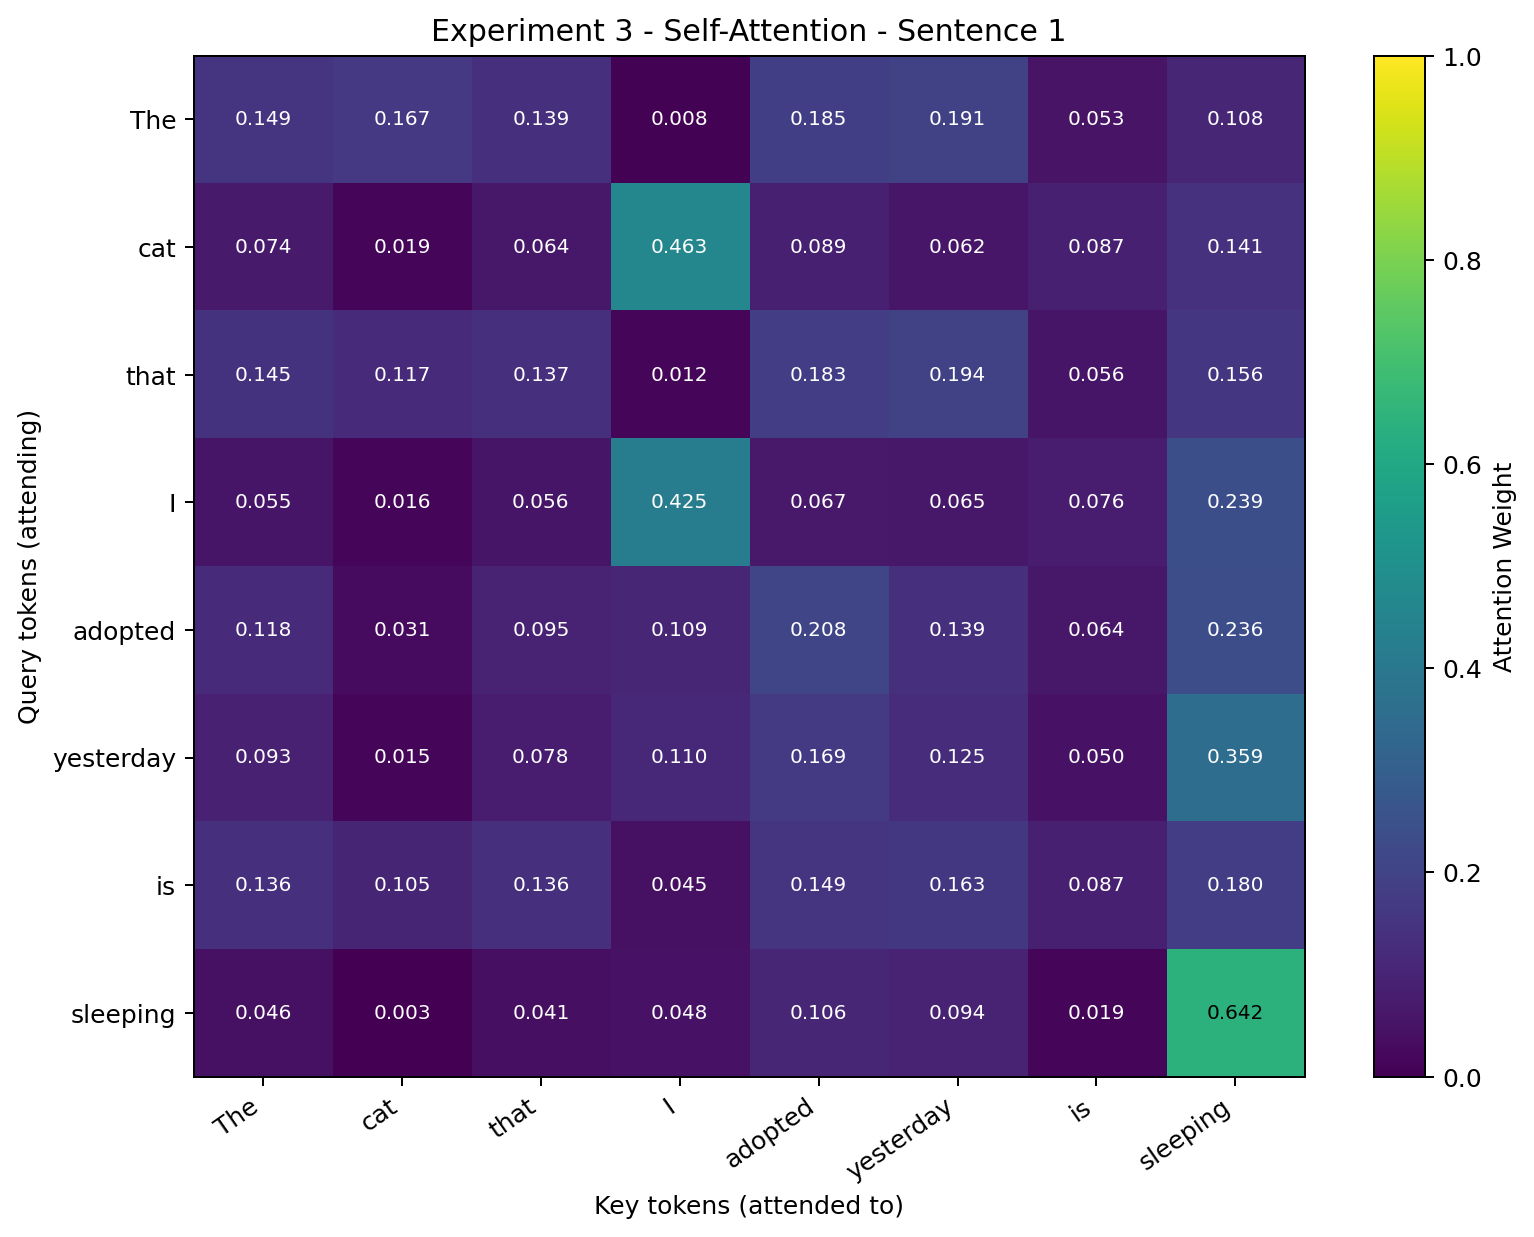

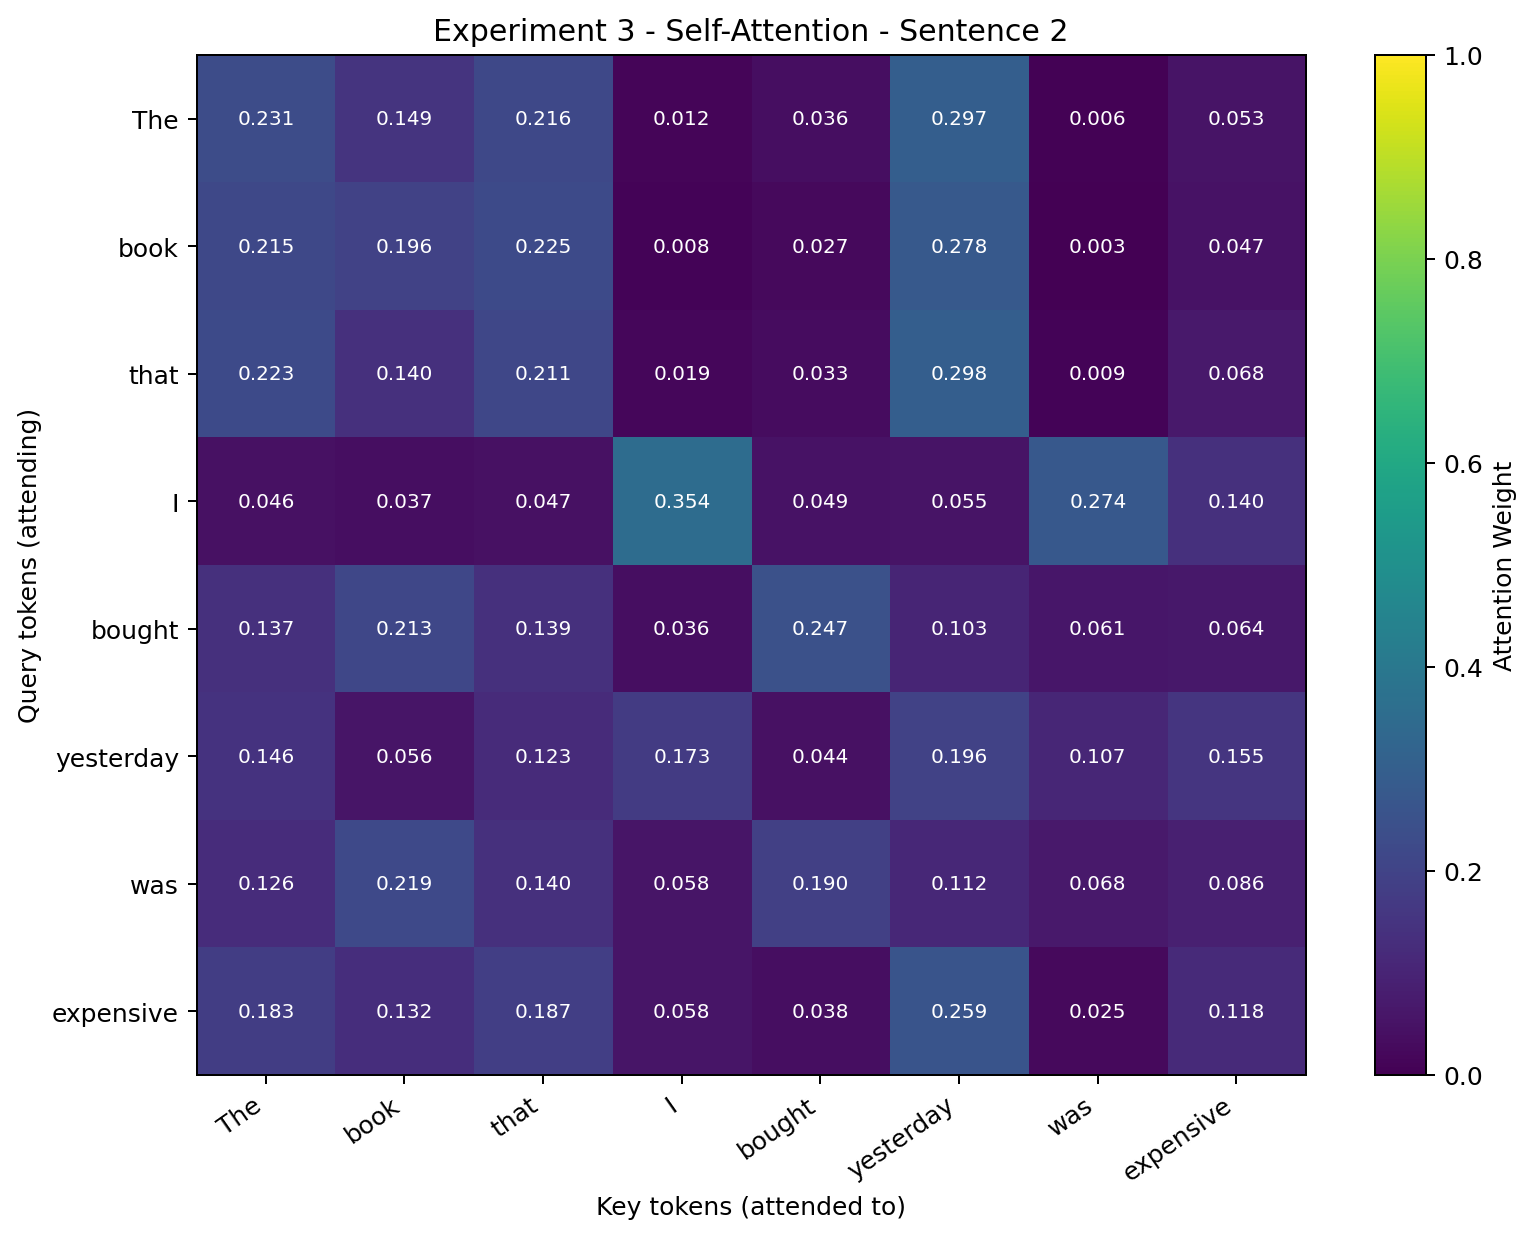

Heatmap 1: /home/nguyenducthang/NLP/Lab6/artifacts/experiment3_attention_heatmap_sentence1.png
Heatmap 2: /home/nguyenducthang/NLP/Lab6/artifacts/experiment3_attention_heatmap_sentence2.png


In [13]:
display(Image(filename=str(E3_RESULT['files']['heatmap_sentence1'])))
display(Image(filename=str(E3_RESULT['files']['heatmap_sentence2'])))
print('Heatmap 1:', E3_RESULT['files']['heatmap_sentence1'])
print('Heatmap 2:', E3_RESULT['files']['heatmap_sentence2'])

## 3. Attention rows for cat, adopted and sleeping

In [14]:
selected_rows_e3 = E3_RESULT['selected_rows']
print(f'{"Source Token":<15} {"Position":>8} {"Attended Token":<15} {"Weight":>12} {"Rank":>6}')
for source, position, attended, weight, rank in selected_rows_e3:
    print(f'{source:<15} {position:>8} {attended:<15} {weight:>12.6f} {rank:>6}')
print('Saved selected-token table:', E3_RESULT['files']['selected_csv'])
print('Full matrix CSVs:', E3_RESULT['files']['matrix_sentence1_csv'], E3_RESULT['files']['matrix_sentence2_csv'])

Source Token    Position Attended Token        Weight   Rank
cat                    1 I                   0.462630      1
cat                    1 sleeping            0.141323      2
cat                    1 adopted             0.089285      3
adopted                4 sleeping            0.236040      1
adopted                4 adopted             0.208250      2
adopted                4 yesterday           0.139009      3
sleeping               7 sleeping            0.641718      1
sleeping               7 adopted             0.106145      2
sleeping               7 yesterday           0.094042      3
Saved selected-token table: /home/nguyenducthang/NLP/Lab6/artifacts/experiment3_selected_token_analysis.csv
Full matrix CSVs: /home/nguyenducthang/NLP/Lab6/artifacts/experiment3_attention_matrix_sentence1.csv /home/nguyenducthang/NLP/Lab6/artifacts/experiment3_attention_matrix_sentence2.csv


## 4. Selected-token comparison visualization

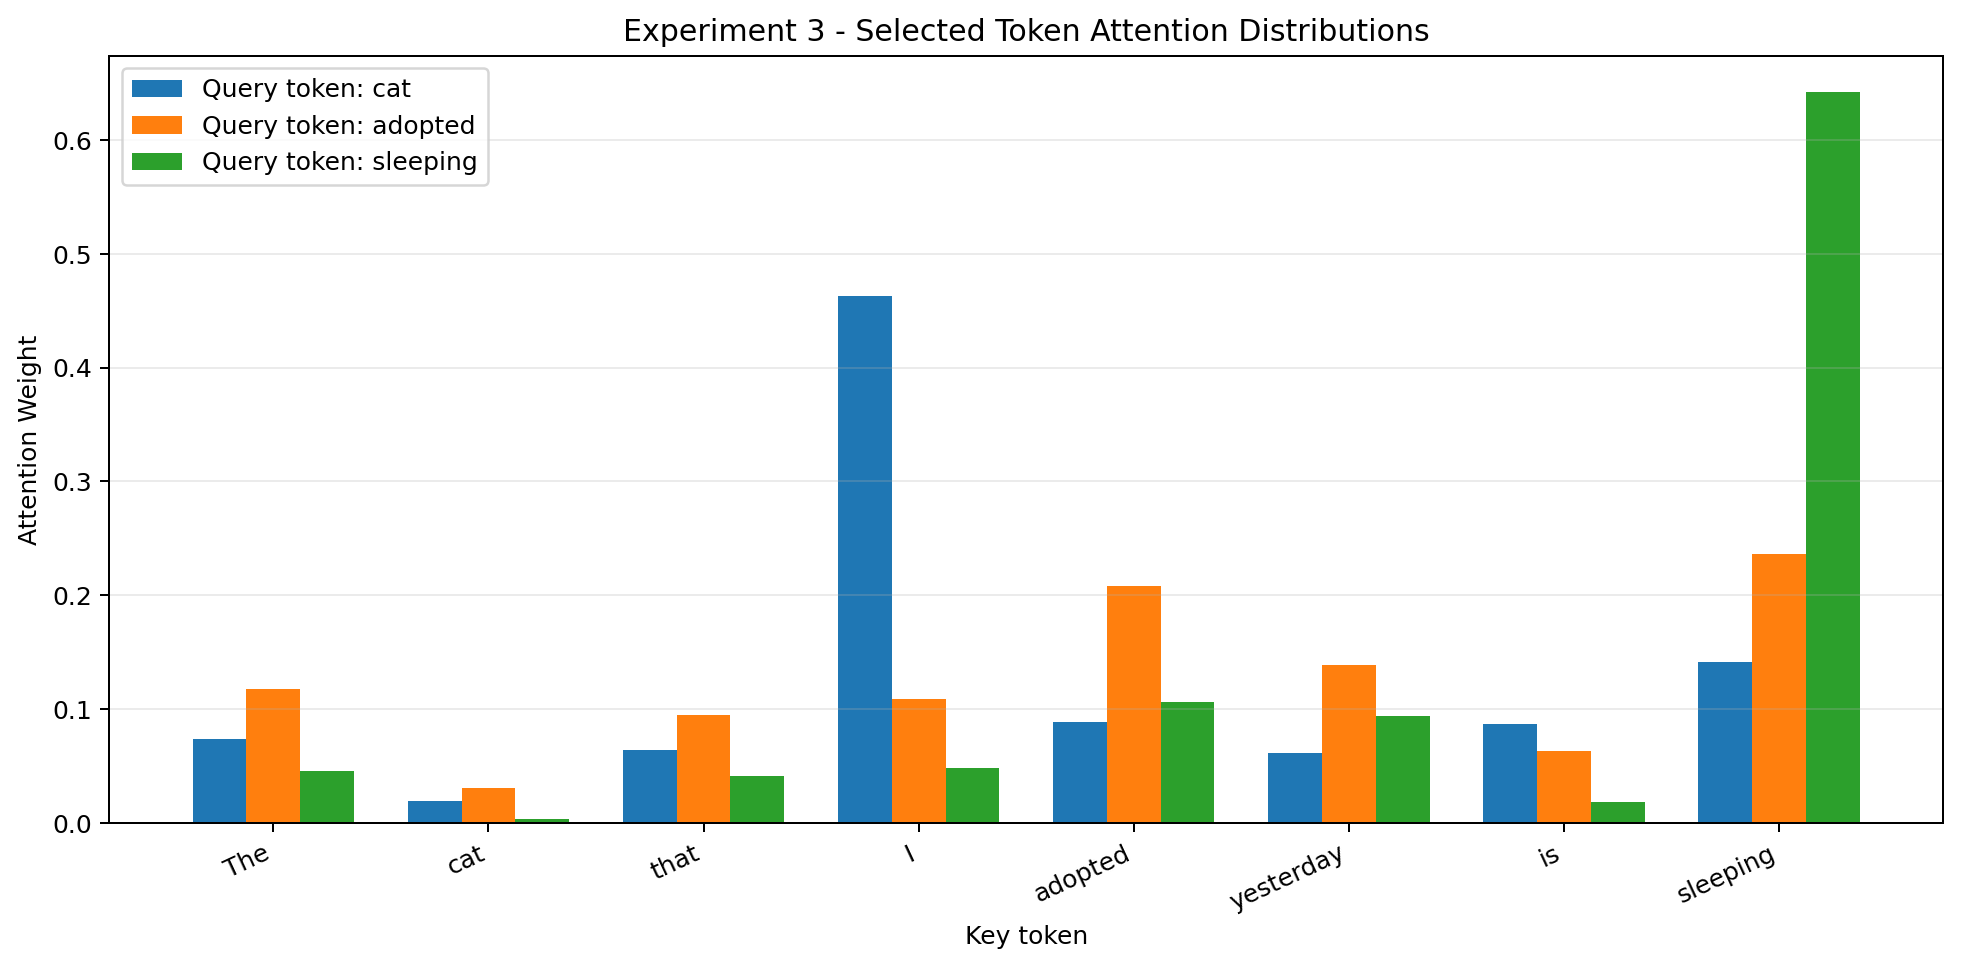

Saved: /home/nguyenducthang/NLP/Lab6/artifacts/experiment3_selected_tokens_comparison.png


In [15]:
display(Image(filename=str(E3_RESULT['files']['selected_comparison'])))
print('Saved:', E3_RESULT['files']['selected_comparison'])

## 5. Verification and regression tests

In [16]:
assert TOKENS1_E3 == ['The', 'cat', 'that', 'I', 'adopted', 'yesterday', 'is', 'sleeping']
assert TOKENS2_E3 == ['The', 'book', 'that', 'I', 'bought', 'yesterday', 'was', 'expensive']
assert len(TOKENS1_E3) == len(TOKENS2_E3) == 8

for output in [E3_RESULT['output1'], E3_RESULT['output2']]:
    q, k, v, scores, weights, context = output
    assert q.shape == k.shape == (8, 4) and v.shape == context.shape == (8, 4)
    assert scores.shape == weights.shape == (8, 8)
    assert np.allclose(weights.sum(axis=1), 1.0, atol=1e-10)
    assert np.all((weights >= 0.0) & (weights <= 1.0))
    assert all(np.all(np.isfinite(array)) for array in output)

# Shared token embeddings and projection matrices are identical across both inputs.
shared_e3 = set(TOKENS1_E3) & set(TOKENS2_E3)
for token in shared_e3:
    assert np.array_equal(X1_E3[TOKENS1_E3.index(token)], E3_RESULT['embeddings'][token])
    assert np.array_equal(X2_E3[TOKENS2_E3.index(token)], E3_RESULT['embeddings'][token])

# Stable softmax must remain finite for large scores.
large_weights_e3 = stable_softmax(np.array([[1000.0, 1001.0, 1002.0]]), axis=-1)
assert np.all(np.isfinite(large_weights_e3)) and np.isclose(large_weights_e3.sum(), 1.0)

# Repeat with the same seed and verify identical parameters/matrices.
emb_again, wq_again, wk_again, wv_again = create_synthetic_parameters(seed=42)
assert all(np.array_equal(E3_RESULT['embeddings'][t], emb_again[t]) for t in E3_RESULT['embeddings'])
assert np.array_equal(E3_RESULT['w_query'], wq_again) and np.array_equal(E3_RESULT['w_key'], wk_again)
assert np.array_equal(E3_RESULT['w_value'], wv_again)
repeat1 = self_attention(X1_E3, wq_again, wk_again, wv_again)
repeat2 = self_attention(X2_E3, wq_again, wk_again, wv_again)
assert np.array_equal(ATTENTION1_E3, repeat1[4]) and np.array_equal(ATTENTION2_E3, repeat2[4])

# Validate selected top-3 rows against the source matrix.
assert all(token in TOKENS1_E3 for token in SELECTED_TOKENS) and len(selected_rows_e3) == 9
for token in SELECTED_TOKENS:
    row_index = TOKENS1_E3.index(token)
    expected = np.argsort(-ATTENTION1_E3[row_index], kind='stable')[:3]
    actual = [row for row in selected_rows_e3 if row[0] == token]
    assert [TOKENS1_E3.index(row[2]) for row in actual] == expected.tolist()
    assert np.allclose([row[3] for row in actual], ATTENTION1_E3[row_index, expected])

# Validate output CSV/PNG shapes and ensure previous experiment files were not touched.
files_e3 = E3_RESULT['files']
assert all(path.is_file() and path.stat().st_size > 0 for path in files_e3.values())
for matrix_key in ['matrix_sentence1_csv', 'matrix_sentence2_csv']:
    with files_e3[matrix_key].open(newline='', encoding='utf-8') as file:
        matrix_rows = list(csv.reader(file))
    assert len(matrix_rows) == 9 and all(len(row) == 9 for row in matrix_rows)
with files_e3['selected_csv'].open(newline='', encoding='utf-8') as file:
    selected_csv_rows = list(csv.reader(file))
assert len(selected_csv_rows) == 10 and all(len(row) == 5 for row in selected_csv_rows)
assert all((ARTIFACTS_DIR / name).read_bytes() == data for name, data in PREVIOUS_E3_BYTES.items())
scores_e1_reg, weights_e1_reg = dot_product_attention(QUERY, KEYS)
scores_a_reg, weights_a_reg = dot_product_attention(QUERY_A, KEYS_E2)
scores_b_reg, weights_b_reg = dot_product_attention(QUERY_B, KEYS_E2)
# Dùng các CSV đã lưu làm mốc; tên scores trong notebook có thể bị cell khác dùng lại.
with (ARTIFACTS_DIR / 'experiment1_attention_distribution.csv').open(newline='', encoding='utf-8') as file:
    e1_rows = list(csv.DictReader(file))
e1_saved_scores = np.array([float(row['Score']) for row in e1_rows])
e1_saved_weights = np.array([float(row['Attention']) for row in e1_rows])
with (ARTIFACTS_DIR / 'experiment2_query_comparison.csv').open(newline='', encoding='utf-8') as file:
    e2_rows = list(csv.DictReader(file))
e2_saved_scores_a = np.array([float(row['Score A']) for row in e2_rows])
e2_saved_weights_a = np.array([float(row['Weight A']) for row in e2_rows])
e2_saved_scores_b = np.array([float(row['Score B']) for row in e2_rows])
e2_saved_weights_b = np.array([float(row['Weight B']) for row in e2_rows])
assert np.allclose(scores_e1_reg, e1_saved_scores, rtol=1e-10, atol=1e-10) and np.allclose(weights_e1_reg, e1_saved_weights, rtol=1e-10, atol=1e-10)
assert np.allclose(scores_a_reg, e2_saved_scores_a, rtol=1e-10, atol=1e-10) and np.allclose(weights_a_reg, e2_saved_weights_a, rtol=1e-10, atol=1e-10)
assert np.allclose(scores_b_reg, e2_saved_scores_b, rtol=1e-10, atol=1e-10) and np.allclose(weights_b_reg, e2_saved_weights_b, rtol=1e-10, atol=1e-10)
print('PASS: tokenization, shapes, row softmax, stability, reproducibility, selected tokens, CSV/PNG, regression Exp1-2')

PASS: tokenization, shapes, row softmax, stability, reproducibility, selected tokens, CSV/PNG, regression Exp1-2


## 6. Gợi ý phân tích cá nhân

Các bảng và heatmap là attention patterns sinh ra từ synthetic embeddings và random projections. Hãy tự mô tả các hàng của `cat`, `adopted`, `sleeping` và đối chiếu với các token có trọng số cao. Không diễn giải trọng số thành quan hệ ngữ pháp đã được mô hình học, hoặc bằng chứng về reasoning/linguistic understanding.

# Experiment 4 — LSTM Context vs Attention Context

So sánh hai classifier trên IMDb và cách chia dữ liệu đã dùng trong LAB 05. Cả hai nhận cùng tokenizer, vocabulary, độ dài tối đa, labels và train/validation/test split. LSTM dùng hidden state cuối trên packed sequence; Attention dùng scaled dot-product self-attention với padding mask, sau đó masked mean pooling. Validation F1 chọn checkpoint; Test chỉ đánh giá sau cùng.

## 1. So sánh cơ chế representation

**LSTM:** token embeddings được xử lý tuần tự; hidden state được cập nhật ở mỗi bước, rồi final hidden state có shape `(batch, hidden_size)` được đưa vào classifier. `pack_padded_sequence` khiến PAD không được xem là timestep hợp lệ.

**Attention:** tính `Q=XWQ`, `K=XWK`, `V=XWV`; `softmax(QKᵀ/√d_k)` tạo attention weights. Context tại từng token là weighted combination của V; masked mean pooling tổng hợp các context hợp lệ thành vector cho classifier. PAD keys bị mask trước softmax và PAD queries bị loại khỏi pooling.

Mô hình Attention này không dùng positional encoding. Vì thế self-attention cùng masked mean pooling không trực tiếp biểu diễn thứ tự token như LSTM. Attention is not guaranteed to outperform LSTM. Representation mechanisms differ even when both models solve the same sentiment classification task.

## 2. Huấn luyện, đánh giá và artifacts

Cell dưới tải IMDb từ Hugging Face (dùng cache nếu có), dựng lại train/validation split theo LAB 05, huấn luyện hai model và lưu kết quả. Cấu hình chung: seed khởi tạo 42, split seed 2026, embedding 50, batch 64, Adam với learning rate 0.001, 3 epochs, max length 100. Chọn checkpoint bằng Validation F1.

In [17]:
import pandas as pd
from experiment4_models import run_experiment4

LAB5_DIR = LAB_DIR.parent / 'Lab5'
E4 = run_experiment4(ARTIFACTS_DIR, LAB5_DIR)

display(E4['results'][[
    'Model', 'Accuracy', 'F1', 'Macro-F1', 'Training Time (s)',
    'Parameters', 'Epochs Trained', 'Best Epoch (Validation F1)'
]].style.format({
    'Accuracy': '{:.4f}', 'F1': '{:.4f}', 'Macro-F1': '{:.4f}',
    'Training Time (s)': '{:.2f}'
}))
display(E4['histories'])
display(pd.DataFrame([E4['config']]))
print('Test report:', ARTIFACTS_DIR / 'experiment4_test_report.txt')
print('Artifacts:', *[str(path) for path in E4['files']], sep='\n- ')

/home/nguyenducthang/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LSTMClassifier epoch 1/3: train_loss=0.6863, val_loss=0.6804, val_f1=0.6146, train_seconds=18.02


LSTMClassifier epoch 2/3: train_loss=0.6140, val_loss=0.5670, val_f1=0.7078, train_seconds=20.17


LSTMClassifier epoch 3/3: train_loss=0.5225, val_loss=0.5379, val_f1=0.7501, train_seconds=17.34


LSTM: best validation-F1 epoch=3; test metrics={'Loss': 0.5563031570243836, 'Accuracy': 0.7152, 'F1': 0.7449308590671347, 'Macro-F1': 0.7112773465850932}


...

PASS: same dataset splits and no sample identity overlap
PASS: same tokenizer, train-only vocabulary, max length and labels
PASS: model input/output shapes
PASS: model input/output shapes
PASS: LSTM final state excludes trailing PAD
PASS: padded keys receive zero weight and padded queries are excluded
PASS: attention weights normalize over valid keys
PASS: LSTM gradient flow is finite
PASS: Attention gradient flow is finite
PASS: finite logits/loss/attention values
PASS: predictions are in label space
PASS: LSTM metrics use the actual test labels
PASS: LSTM parameter count is from the model
PASS: LSTM training time is measured and positive
PASS: Attention metrics use the actual test labels
PASS: Attention parameter count is from the model
PASS: Attention training time is measured and positive
PASS: all result files exist and are non-empty
PASS: fixed seed produces identical model initialization
PASS: Experiment 1-3 artifacts remain byte-identical


,Model,Accuracy,F1,Macro-F1,Training Time (s),Parameters,Epochs Trained,Best Epoch (Validation F1)
0,LSTM,0.7152,0.7449,0.7113,57.75,1029761,3,3
1,Attention,0.7899,0.7929,0.7898,7.83,1007551,3,3


,Model,Epoch,Train Loss,Validation Loss,Validation Accuracy,Validation F1,Validation Macro-F1,Epoch Training Time (s)
0,LSTM,1,0.686269,0.680450,0.5684,0.614643,0.562094,18.021362
1,LSTM,2,0.614035,0.566984,0.7196,0.707795,0.719142,20.168774
2,LSTM,3,0.522474,0.537878,0.7206,0.750134,0.716641,17.338338
3,Attention,1,0.611796,0.513281,0.7478,0.751723,0.747737,2.444439
4,Attention,2,0.453229,0.431403,0.7988,0.805792,0.798539,2.423433
5,Attention,3,0.369326,0.403051,0.8210,0.825502,0.820881,2.402740


,dataset,original_train_samples,train_samples,validation_samples,test_samples,num_classes,label_mapping,split,lab5_reference_files,lab5_original_lstm_checkpoint_reused,...,attention_qk_v_dim,batch_size,learning_rate,optimizer,epochs,loss,early_stopping,checkpoint_selection,attention,lab5_source_not_modified
0,IMDb (Hugging Face imdb; train and test labele...,25000,20000,5000,25000,2,"{'0': 'Negative', '1': 'Positive'}",IMDb train split stratified 80/20 with seed 20...,[/home/nguyenducthang/NLP/Lab5/sequence_classi...,False,...,50,64,0.001,Adam,3,BCEWithLogitsLoss,False,"best validation binary F1, positive label 1",single-head scaled dot-product; no positional ...,True


Test report: /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_test_report.txt
Artifacts:
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_results.csv
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_training_history.csv
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_training_loss.png
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_validation_f1.png
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_confusion_matrix_lstm.png
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_confusion_matrix_attention.png
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_attention_matrix.csv
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_trained_attention_heatmap.png
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_representation_inspection.csv
- /home/nguyenducthang/NLP/Lab6/artifacts/experiment4_config.json
- /home/nguyenducthang/NLP/Lab6/artifacts/checkpoints/experiment4_lstm.pt
- /home/nguyenducthang/NLP/Lab6/artifacts/checkpoints/experiment4_attention

## 3. Cùng test sample và visualizations

`experiment4_representation_inspection.csv` ghi ground truth, hai dự đoán/xác suất và shape của hai representations trên cùng một review. Heatmap dưới đây đến từ Attention Classifier đã train, khác với random attention của Experiment 3. Attention weights cho biết phân phối theo phép tính của model; tự kiểm tra review và ma trận trước khi viết nhận xét, và không xem heatmap là bằng chứng về linguistic reasoning.

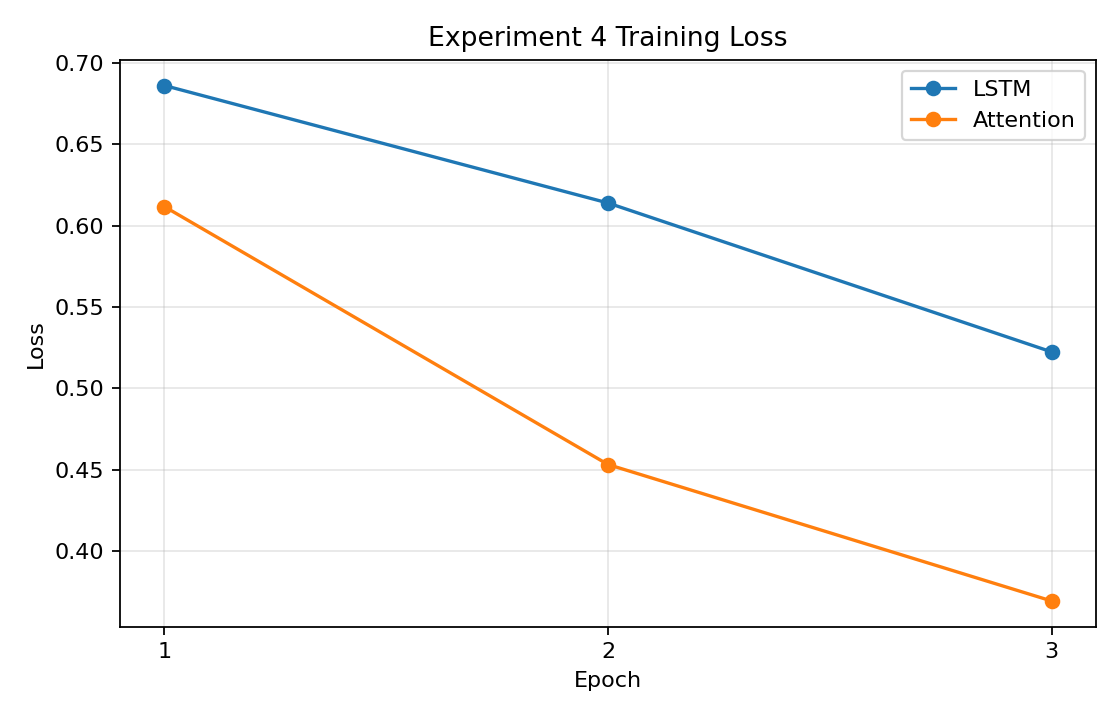

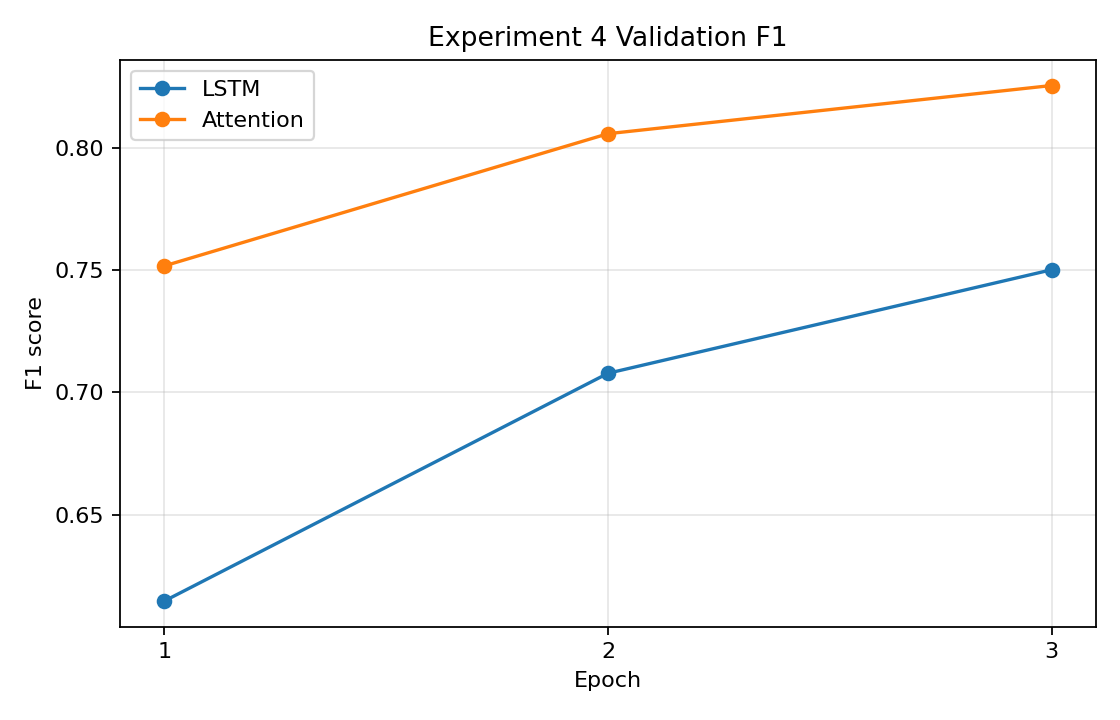

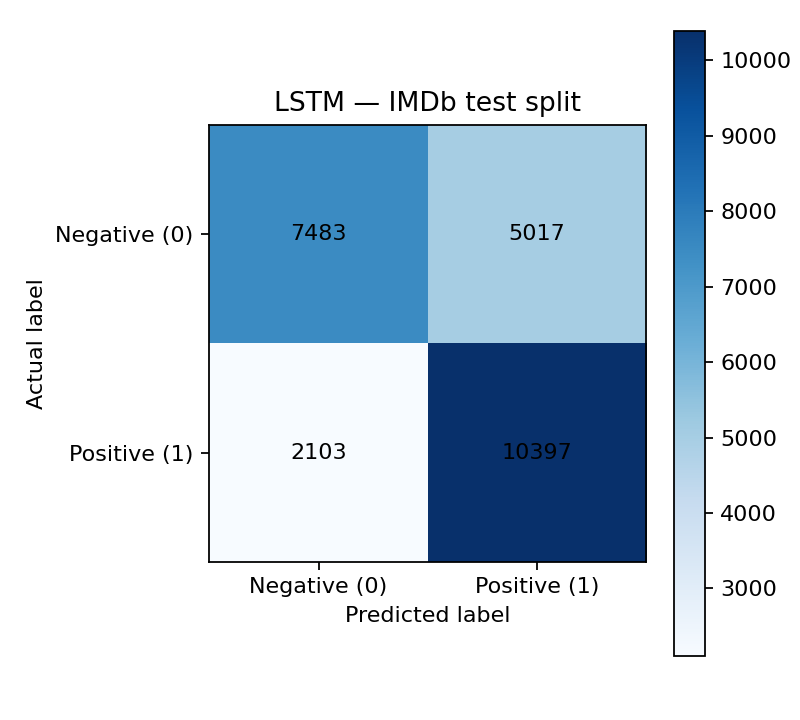

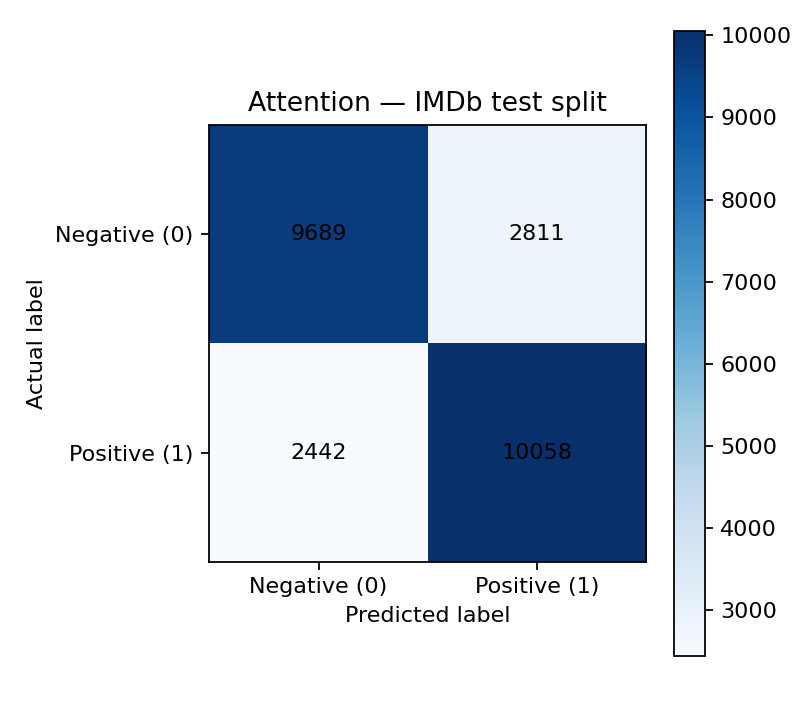

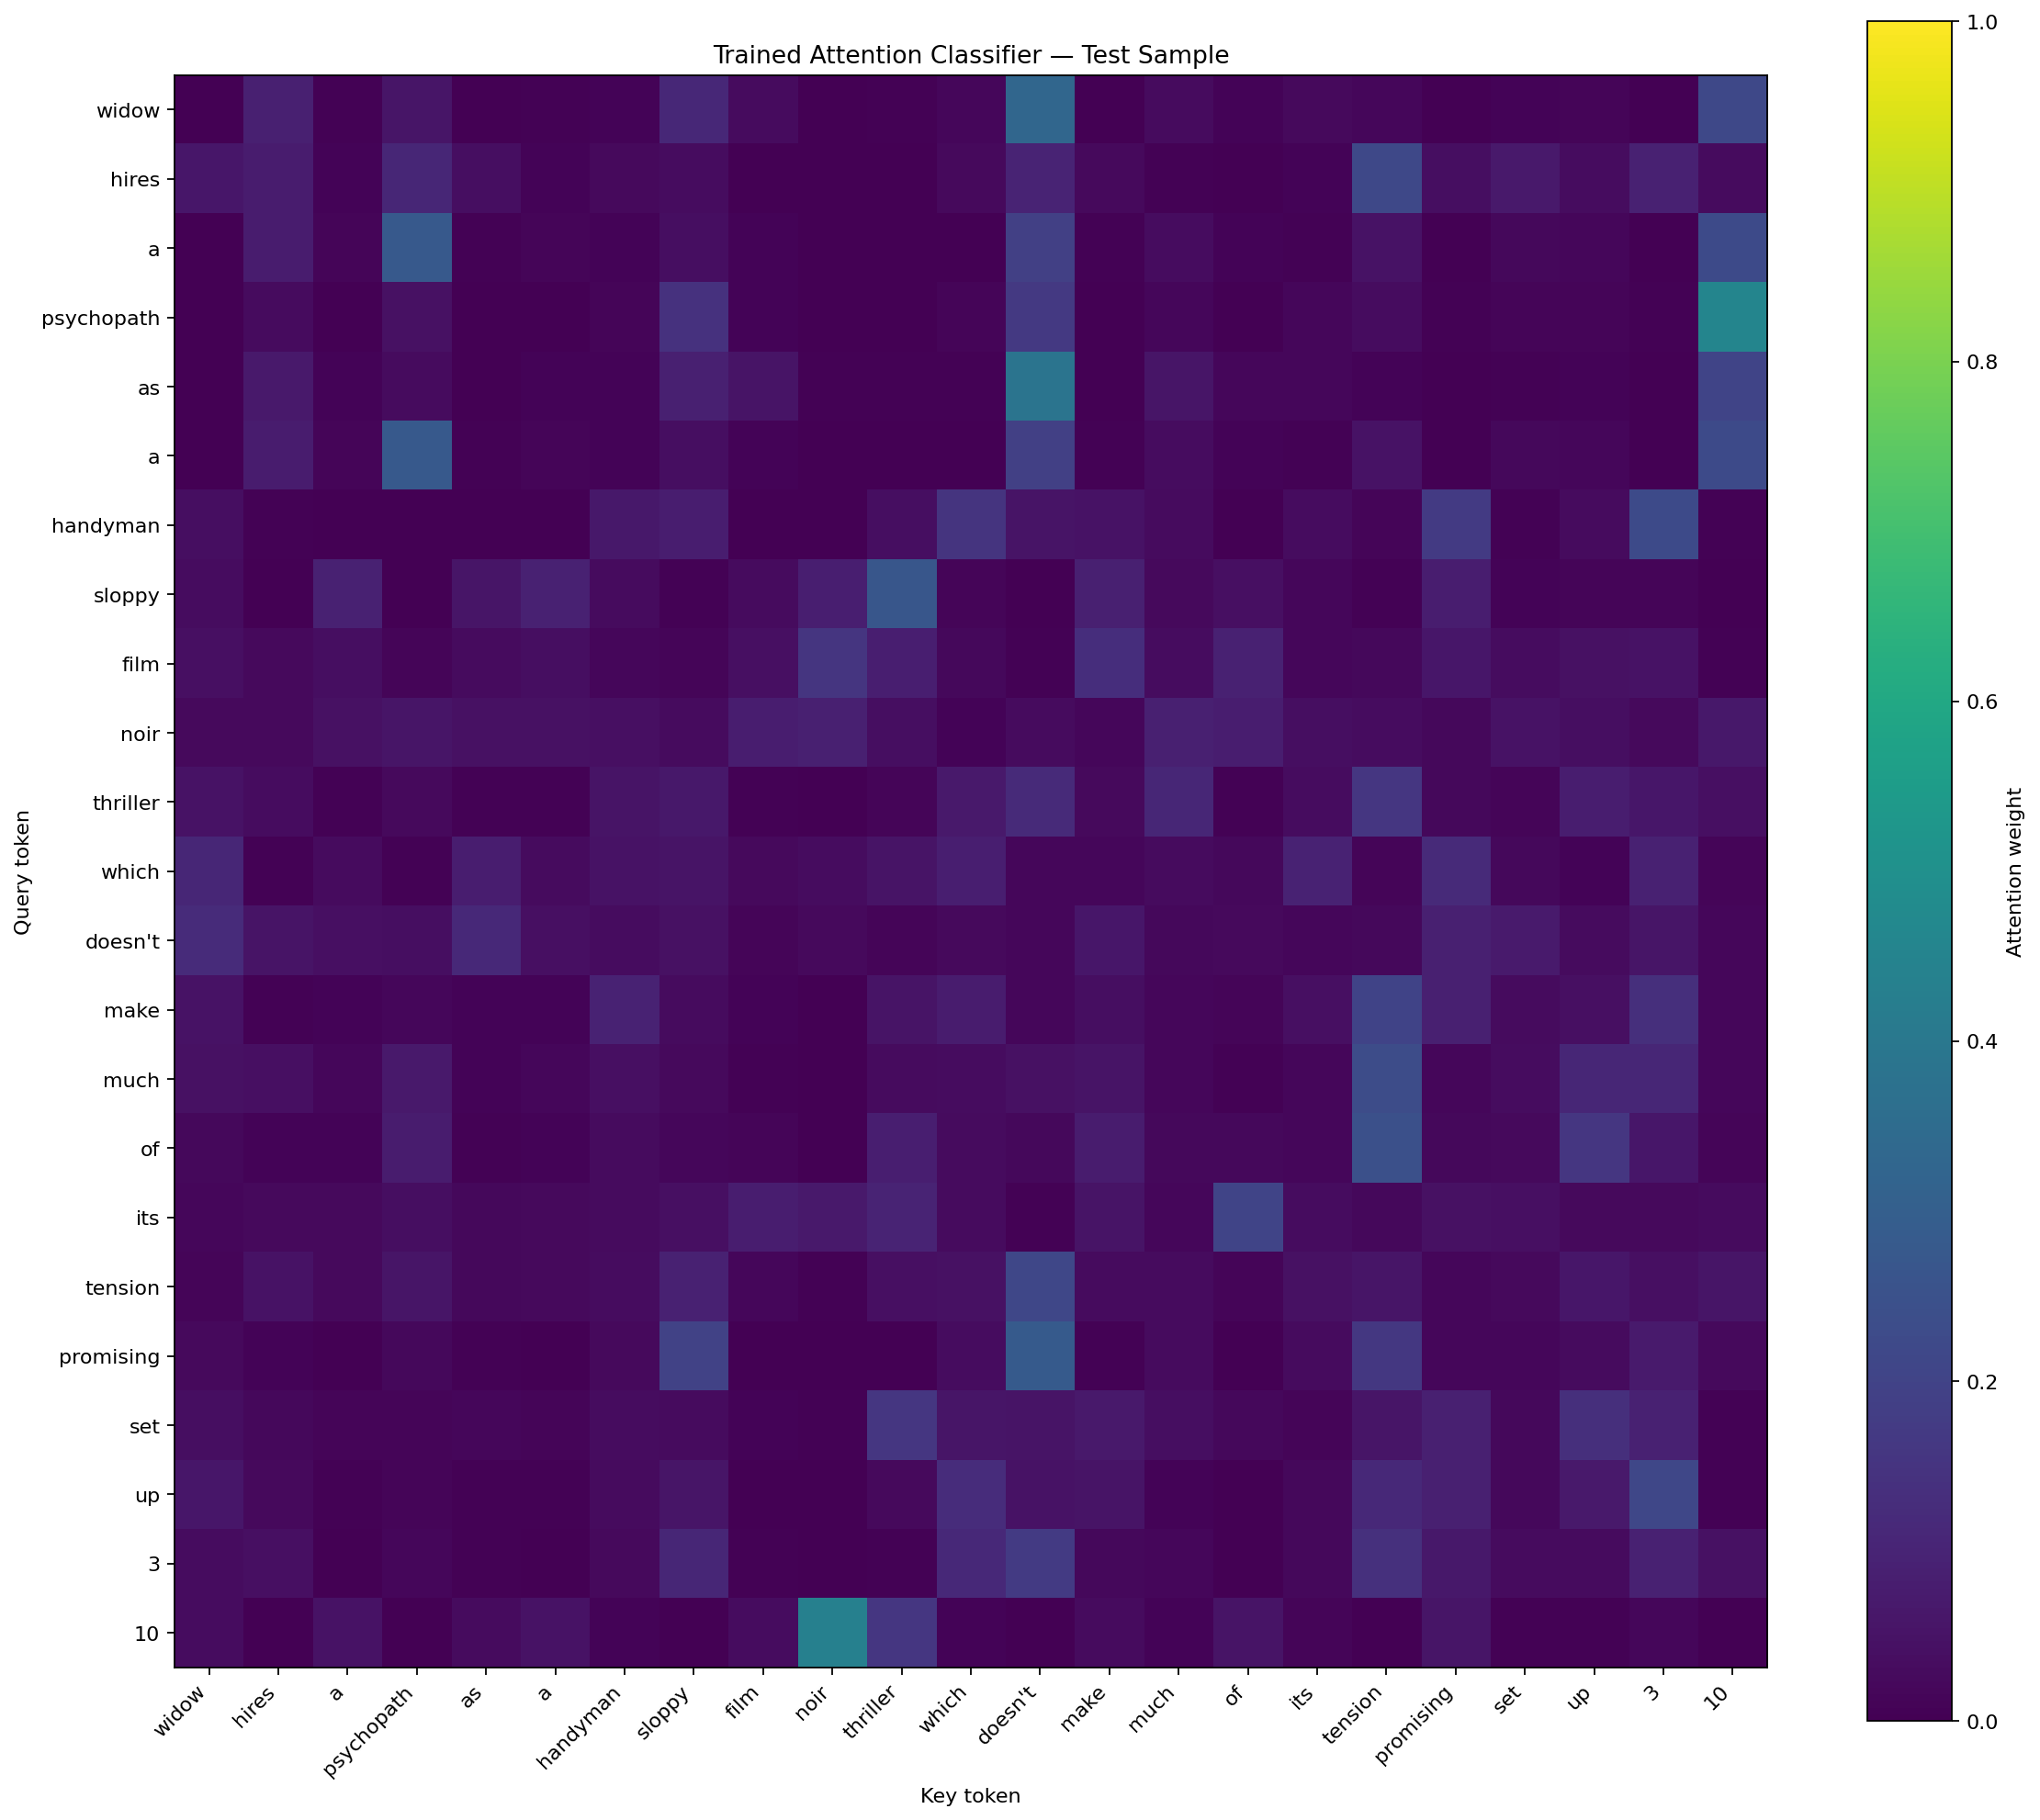

,Test row index,Ground truth,Attention prediction,Attention P(positive),Attention context shape,Token count shown,Tokens,LSTM prediction,LSTM P(positive),LSTM final hidden shape
0,41,0,0,0.169479,"(1, 50)",23,widow hires a psychopath as a handyman sloppy ...,0,0.180321,"(1, 64)"


In [18]:
display(Image(filename=str(ARTIFACTS_DIR / 'experiment4_training_loss.png')))
display(Image(filename=str(ARTIFACTS_DIR / 'experiment4_validation_f1.png')))
display(Image(filename=str(ARTIFACTS_DIR / 'experiment4_confusion_matrix_lstm.png')))
display(Image(filename=str(ARTIFACTS_DIR / 'experiment4_confusion_matrix_attention.png')))
display(Image(filename=str(ARTIFACTS_DIR / 'experiment4_trained_attention_heatmap.png')))
display(pd.read_csv(ARTIFACTS_DIR / 'experiment4_representation_inspection.csv').drop(columns=['Text']))

## 4. Câu hỏi để tự phân tích

- LSTM tạo sequence representation bằng cách nào? Attention context được tạo và gộp ra sao?
- Vì sao final hidden state và masked mean của contextual values là các phép biểu diễn khác nhau?
- Hai mô hình thể hiện thông tin thứ tự như nhau không? Nêu giới hạn của Attention-only baseline không positional encoding.
- Accuracy/F1, số parameters và thời gian thực tế khác nhau thế nào? Không giả định model nào luôn tốt hơn.
- Với review trong representation inspection, các prediction và attention row nào là evidence quan sát được?

### AI Assistance Statement

- Tool: OpenAI Codex.
- Purpose: hỗ trợ implementation, debugging, kiểm thử và visualization.
- Generated: code mô hình/train/evaluation cho Experiment 4 và cấu trúc báo cáo kết quả.
- Modified: tái sử dụng cách chia, tokenizer, vocabulary policy và cấu hình LAB 05; giữ riêng artifacts E4.
- Verified: chạy huấn luyện/evaluation thực tế, kiểm tra masking, padding, gradient, metrics, artifacts và regression E1–E3.

Hãy tự viết interpretation cuối cùng dựa trên các số liệu đã lưu; không coi đây là reflection cá nhân soạn sẵn.